In [6]:
%pip install opencv-python


  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl (44.0 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


POINT (35.68606948852539 -78.87804412841797)


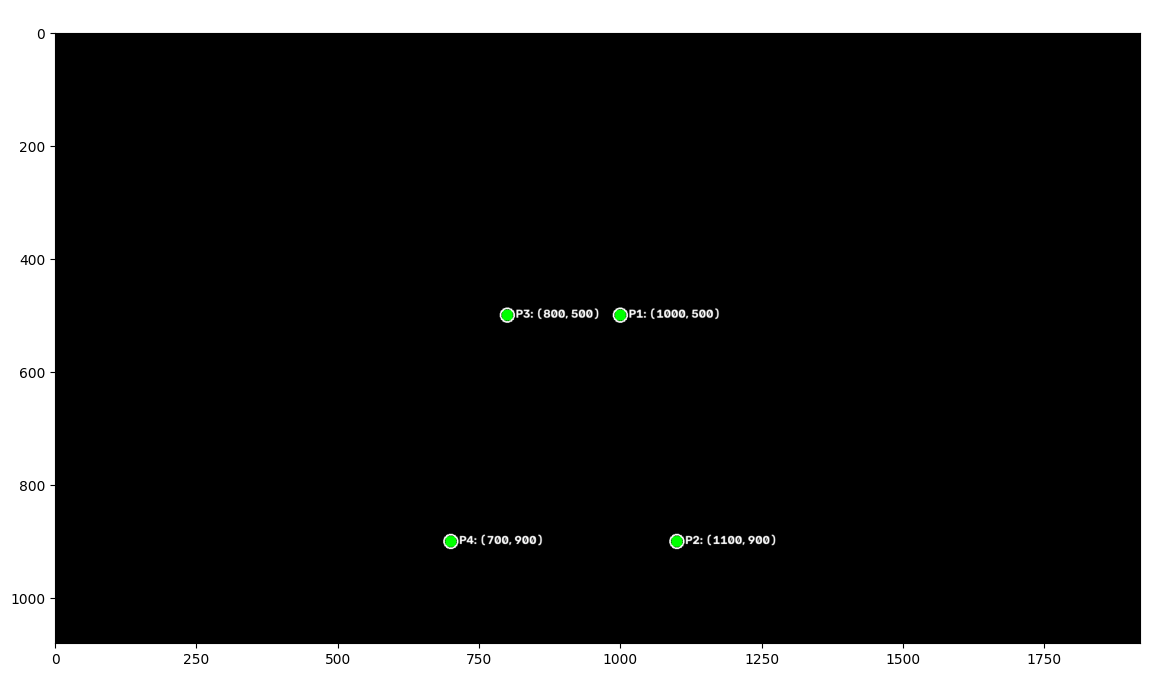

In [ ]:
import cv2
import numpy as np
from shapely.geometry import Point

class ReferencePoint: 
    pixel_coords    = None  # (x, y)
    point           = None  # shapely.geometry.Point
    def __init__(self, coords=None, point=None): 
        self.pixel_coords   = coords
        self.point          = point

class Camera:
    resolution = (1920, 1080)
    reference_points = []

    def __init__(self, resolution=None, reference_points=None):
        self.resolution         = resolution if resolution else (1920, 1080)
        self.reference_points   = reference_points if reference_points else []

    def add_reference_point(self, reference_point):
        self.reference_points.append(reference_point)

    def pixel_to_geo(self, pixel_coords):
        """
        Calculates the geographic location (latitude, longitude) for a given 
        pixel coordinate using the camera's reference points via homography.
        """
        if len(self.reference_points) < 4:
            raise ValueError("At least 4 reference points are required to compute a homography matrix.")
        
        src_pts = []
        dst_pts = []
        
        for rp in self.reference_points:
            if rp.pixel_coords is not None and rp.point is not None:
                src_pts.append(list(rp.pixel_coords))
                # Note: Using point.x as Latitude and point.y as Longitude based on your Point initialization
                dst_pts.append([rp.point.x, rp.point.y])
                
        # OpenCV requires numpy arrays of shape (N, 1, 2) for homography/perspective transform
        src_pts = np.array(src_pts, dtype=np.float32).reshape(-1, 1, 2)
        dst_pts = np.array(dst_pts, dtype=np.float32).reshape(-1, 1, 2)
        
        # Compute the homography matrix mapping pixels -> geographic coordinates
        matrix, _ = cv2.findHomography(src_pts, dst_pts)
        
        if matrix is None:
            raise RuntimeError("Could not compute homography matrix. Check reference points.")
            
        # Format the target pixel coordinate
        target_pixel = np.array([[list(pixel_coords)]], dtype=np.float32)
        
        # Project pixel coordinates into geographic space
        transformed = cv2.perspectiveTransform(target_pixel, matrix)
        lat, lon = transformed[0][0]
        
        # Return as a Shapely Point (matching your reference point format)
        return Point(lat, lon)

    def visualize_reference_points(self):
        # Unpack resolution (Width, Height)
        width, height = self.resolution
        
        # Create a black image. Note: OpenCV shape expects (Height, Width, Channels)
        canvas = np.zeros((height, width, 3), dtype=np.uint8)
        
        # Loop through each reference point and draw it
        for i, ref_pt in enumerate(self.reference_points):
            if ref_pt.pixel_coords is not None:
                x, y = ref_pt.pixel_coords
                
                # Draw a bright green filled circle at the pixel coordinate
                cv2.circle(canvas, (x, y), 10, (0, 255, 0), -1)
                
                # Draw a white outline around the circle for better visibility
                cv2.circle(canvas, (x, y), 12, (255, 255, 255), 2)
                
                # Add a text label next to the point
                label = f"P{i+1}: {ref_pt.pixel_coords}"
                cv2.putText(canvas, label, (x + 15, y + 5), 
                            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)

        # Convert BGR (OpenCV format) to RGB (Matplotlib format)
        canvas_rgb = cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB)
        
        # Plot using matplotlib for clean notebook rendering
        plt.figure(figsize=(14, 8))
        plt.imshow(canvas_rgb)
        plt.title(f"Camera Reference Points Overlay ({width}x{height})", fontsize=14, color='white')
        plt.axis("on")
        plt.show()

resolution          = (1920, 1080)
top_left_point      = ReferencePoint(coords=(1000, 500), point=Point(35.68580829730078, -78.87812352331412))
top_right_point     = ReferencePoint(coords=(1100, 900), point=Point(35.68580121696315, -78.87783719750352))
bottom_left_point   = ReferencePoint(coords=(800, 500), point=Point(35.68573858317978, -78.8781315699411))
bottom_right_point  = ReferencePoint(coords=(700, 900), point=Point(35.685730958194085, -78.87784122081702))
reference_points = [
    top_left_point,
    top_right_point, 
    bottom_left_point, 
    bottom_right_point,
]
camera = Camera(resolution=resolution, reference_points=reference_points)

print(camera.pixel_to_geo((1910, 540)))
camera.visualize_reference_points()